# ⚡ EV Charging – Machine Learning & Demand Prediction

## Project Overview

This project applies machine learning to electric vehicle (EV) charging data to develop two predictive solutions:

- **Regression:** Predict the energy consumption of a charging session in kilowatt-hours (kWh).
- **Classification:** Categorize a charging session as **High** or **Normal** demand.

The workflow includes data cleaning, exploratory data analysis (EDA), feature engineering, model training, performance evaluation, model explainability using SHAP and LIME, and exporting trained models for the Streamlit dashboard.

In [ ]:
import pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from imblearn.pipeline import make_pipeline     

## Step 1 – Load the data


In [3]:
df = pd.read_csv("ChargingRecords.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (72856, 13)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  object 
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  object 
 6   StartTime       72856 non-null  object 
 7   EndDay          72856 non-null  object 
 8   EndTime         72856 non-null  object 
 9   StartDatetime   72856 non-null  object 
 10  EndDatetime     72856 non-null  object 
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), int64(5), object(7)
memory usage: 7.2+ MB


In [5]:
df.describe().round(2)

,UserID,ChargerID,ChargerCompany,ChargerType,Duration,Demand
count,72856.00,72856.00,72856.00,72856.00,72856.00,72856.00
mean,338.16,525.49,0.63,0.21,151.19,17.44
std,553.97,569.54,0.48,0.40,146.43,13.49
min,0.00,1.00,0.00,0.00,-29.00,0.01
25%,0.00,107.00,0.00,0.00,40.00,7.53
50%,62.00,301.00,1.00,0.00,112.00,14.10
75%,407.00,738.00,1.00,0.00,202.00,23.20
max,2501.00,2671.00,1.00,1.00,1573.00,97.00


## Step 2 – Clean the data


> 

In [6]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# text -> real date/time
df["Start"] = pd.to_datetime(df["StartDay"] + " " + df["StartTime"])
df["End"]   = pd.to_datetime(df["EndDay"] + " " + df["EndTime"])
df["Location"] = df["Location"].str.strip().str.lower()

# recalculate Duration (minutes)
new_duration = (df["End"] - df["Start"]).dt.total_seconds() / 60
print("Rows where the stored Duration was wrong:", ((df["Duration"] - new_duration).abs() > 2).sum())
df["Duration"] = new_duration

Missing values: 0
Duplicate rows: 13
Rows where the stored Duration was wrong: 2813


In [ ]:
# remove impossible rows: zero/negative duration, longer than 3 days, no energy, or power above 200 kW
df = df[(df["Duration"] > 0) & (df["Duration"] <= 72 * 60) & (df["Demand"] > 0)]
df["Power_kW"] = df["Demand"] / (df["Duration"] / 60)
df = df[df["Power_kW"] <= 200]

df = df.sort_values("Start").reset_index(drop=True)      
print("Rows after cleaning:", len(df))

Rows after cleaning: 72746


## Step 3 – Exploratory Data Analysis (EDA)


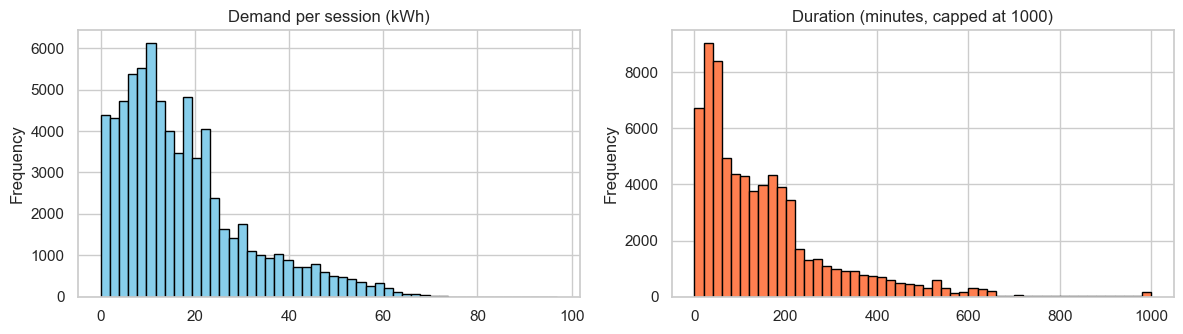

In [8]:
df["Hour"] = df["Start"].dt.hour
df["DayOfWeek"] = df["Start"].dt.dayofweek        # 0 = Monday ... 6 = Sunday
df["Month"] = df["Start"].dt.month

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))

df["Demand"].plot.hist(
    bins=50,
    ax=ax[0],
    color="skyblue",
    edgecolor="black",
    title="Demand per session (kWh)"
)

df["Duration"].clip(upper=1000).plot.hist(
    bins=50,
    ax=ax[1],
    color="coral",
    edgecolor="black",
    title="Duration (minutes, capped at 1000)"
)

plt.tight_layout()
plt.show()

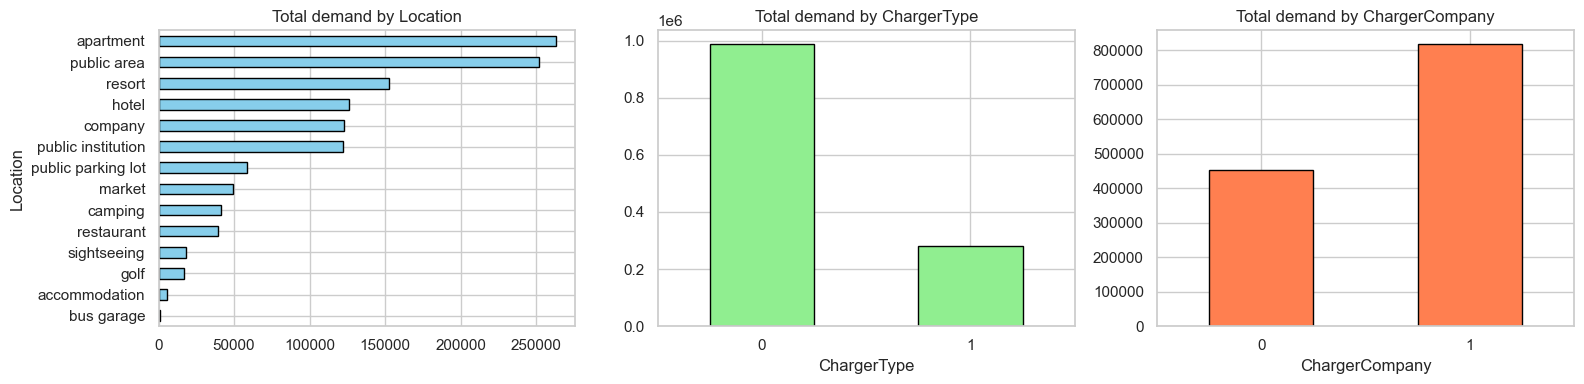

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

df.groupby("Location")["Demand"].sum().sort_values().plot.barh(
    ax=ax[0],
    title="Total demand by Location",
    color="skyblue",
    edgecolor="black"
)

df.groupby("ChargerType")["Demand"].sum().plot.bar(
    ax=ax[1],
    title="Total demand by ChargerType",
    color="lightgreen",
    edgecolor="black",
    rot=0
)

df.groupby("ChargerCompany")["Demand"].sum().plot.bar(
    ax=ax[2],
    title="Total demand by ChargerCompany",
    color="coral",
    edgecolor="black",
    rot=0
)

plt.tight_layout()
plt.show()

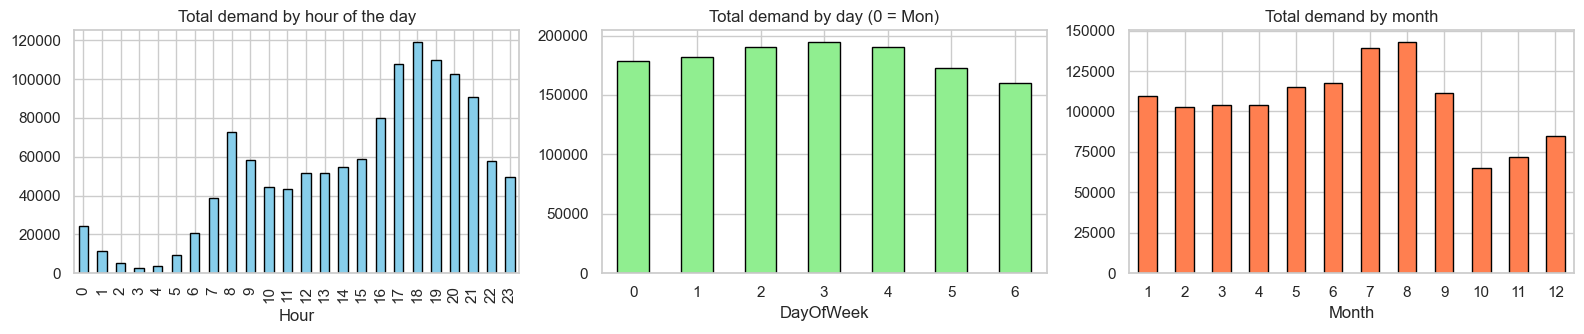

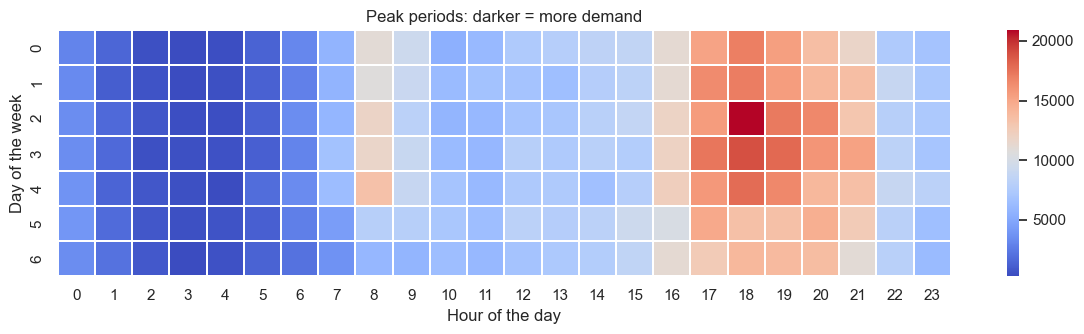

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))

df.groupby("Hour")["Demand"].sum().plot.bar(
    ax=ax[0],
    title="Total demand by hour of the day",
    color="skyblue",
    edgecolor="black"
)

df.groupby("DayOfWeek")["Demand"].sum().plot.bar(
    ax=ax[1],
    title="Total demand by day (0 = Mon)",
    color="lightgreen",
    edgecolor="black",
    rot=0
)

df.groupby("Month")["Demand"].sum().plot.bar(
    ax=ax[2],
    title="Total demand by month",
    color="coral",
    edgecolor="black",
    rot=0
)

plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 3.5))

sns.heatmap(
    df.pivot_table(
        index="DayOfWeek",
        columns="Hour",
        values="Demand",
        aggfunc="sum"
    ),
    cmap="coolwarm",
    linewidths=0.3,
    linecolor="white"
)

plt.title("Peak periods: darker = more demand")
plt.xlabel("Hour of the day")
plt.ylabel("Day of the week")
plt.tight_layout()
plt.show()

## Step 4 – Create new columns (feature engineering)


In [13]:
df["Day"] = df["Start"].dt.day
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)
df["TimeOfDay"] = np.select([df["Hour"].between(5, 11), df["Hour"].between(12, 16), df["Hour"].between(17, 21)],
                            ["Morning", "Afternoon", "Evening"], default="Night")

# average of the PREVIOUS sessions (shift() hides the current row)
past_mean = lambda col, who: df.groupby(who)[col].transform(lambda s: s.shift().expanding().mean())
df["Charger_prev_mean"]    = past_mean("Demand", "ChargerID")
df["User_prev_mean"]       = past_mean("Demand", "UserID")
df["User_prev_duration"]   = past_mean("Duration", "UserID")
df["Charger_prev_count"]   = df.groupby("ChargerID").cumcount()     # how many sessions before this one
df["User_prev_count"]      = df.groupby("UserID").cumcount()

df["IsAnonymous"] = (df["UserID"] == 0).astype(int)
guest = df["IsAnonymous"] == 1
df.loc[guest, "User_prev_mean"] = np.nan
df.loc[guest, "User_prev_duration"] = np.nan
df.loc[guest, "User_prev_count"] = 0

df[["Start", "Location", "Demand", "TimeOfDay", "Charger_prev_mean", "User_prev_mean", "IsAnonymous"]].tail()

,Start,Location,Demand,TimeOfDay,Charger_prev_mean,User_prev_mean,IsAnonymous
72741,2022-09-30 21:49:59,hotel,6.00,Evening,17.274126,NaN,1
72742,2022-09-30 22:10:38,public parking lot,15.79,Night,17.558621,15.676667,0
72743,2022-09-30 22:31:03,public area,5.83,Night,21.327979,NaN,1
72744,2022-09-30 22:37:45,resort,8.49,Night,17.578818,NaN,0
72745,2022-09-30 23:11:59,public institution,0.10,Night,23.977626,NaN,1


## Step 5 – Train / test split 


In [14]:
inputs = ["ChargerCompany", "ChargerType", "Hour", "Day", "Month", "DayOfWeek", "IsWeekend",
          "Charger_prev_mean", "Charger_prev_count", "User_prev_mean", "User_prev_duration",
          "User_prev_count", "IsAnonymous", "Location", "TimeOfDay"]
X = pd.get_dummies(df[inputs], dtype=int)

split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = df["Demand"].iloc[:split], df["Demand"].iloc[split:]

fill_values = X_train.mean()                       # learned from training data only
X_train, X_test = X_train.fillna(fill_values), X_test.fillna(fill_values)

print("Train:", X_train.shape, "from", df["Start"].iloc[0].date(), "to", df["Start"].iloc[split - 1].date())
print("Test :", X_test.shape,  "from", df["Start"].iloc[split].date(), "to", df["Start"].iloc[-1].date())

Train: (58196, 31) from 2021-09-30 to 2022-07-30
Test : (14550, 31) from 2022-07-30 to 2022-09-30


## Step 6 – Regression: predict the energy 


In [15]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest":     RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=10, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, max_depth=4, learning_rate=0.08, subsample=0.8, random_state=42),
    "XGBoost":           XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42),
    "LightGBM":          LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=42, verbose=-1),
}

reg_pipes, reg_scores = {}, {}
for name, model in reg_models.items():
    pipe = make_pipeline(StandardScaler(), model).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    reg_pipes[name] = pipe
    reg_scores[name] = {"MAE": mean_absolute_error(y_test, pred), "MSE": mse, "RMSE": mse ** 0.5, "R2": r2_score(y_test, pred)}

reg_results = pd.DataFrame(reg_scores).T.sort_values("R2", ascending=False).round(3)
reg_results

,MAE,MSE,RMSE,R2
LightGBM,8.173,126.142,11.231,0.348
Random Forest,8.191,126.904,11.265,0.344
Gradient Boosting,8.549,130.399,11.419,0.326
XGBoost,8.523,131.554,11.470,0.320
Linear Regression,8.549,132.258,11.500,0.317


Best regression model: LightGBM  (R2 = 0.348, average mistake = 8.173 kWh)
Guessing the average every time would be wrong by 10.9 kWh on average.


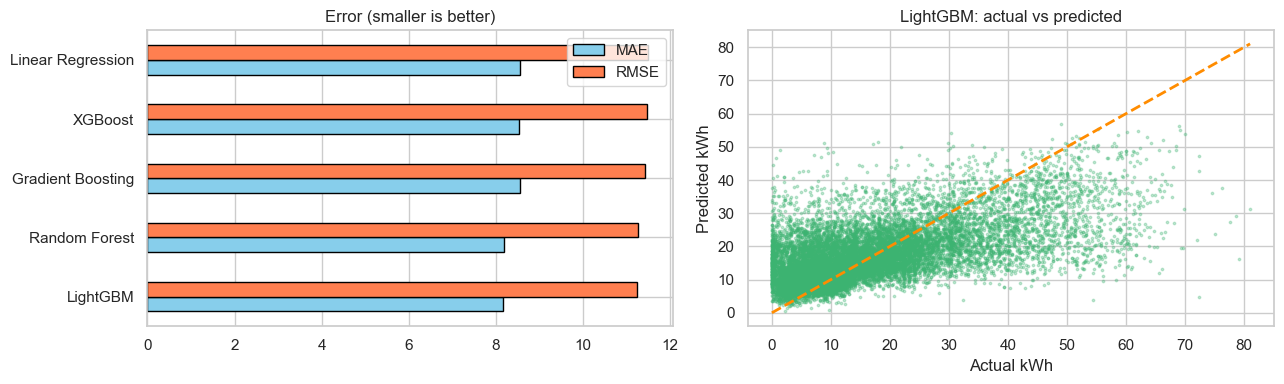

In [17]:
best_reg = reg_results["R2"].idxmax()
reg_pred = reg_pipes[best_reg].predict(X_test)

print(f"Best regression model: {best_reg}  (R2 = {reg_results.loc[best_reg, 'R2']}, average mistake = {reg_results.loc[best_reg, 'MAE']} kWh)")
print(f"Guessing the average every time would be wrong by {mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())):.1f} kWh on average.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

reg_results[["MAE", "RMSE"]].plot.barh(
    ax=ax[0],
    title="Error (smaller is better)",
    color=["skyblue", "coral"],
    edgecolor="black"
)

ax[1].scatter(
    y_test,
    reg_pred,
    s=3,
    alpha=0.3,
    color="mediumseagreen"
)

ax[1].plot(
    [0, y_test.max()],
    [0, y_test.max()],
    color="darkorange",
    linestyle="--",
    linewidth=2
)

ax[1].set(
    xlabel="Actual kWh",
    ylabel="Predicted kWh",
    title=f"{best_reg}: actual vs predicted"
)

plt.tight_layout()
plt.show()

## Step 7 – Create the High / Normal column (classification target)
We compare every session with the **average (mean) demand of the training data**:
* `Demand ≥ mean` → **High**
* `Demand < mean` → **Normal**



Mean demand (training data) = 17.37 kWh
DemandLevel
Normal    42476
High      30270
Name: count, dtype: int64
DemandLevel
Normal    58.4 %
High      41.6 %
Name: proportion, dtype: object


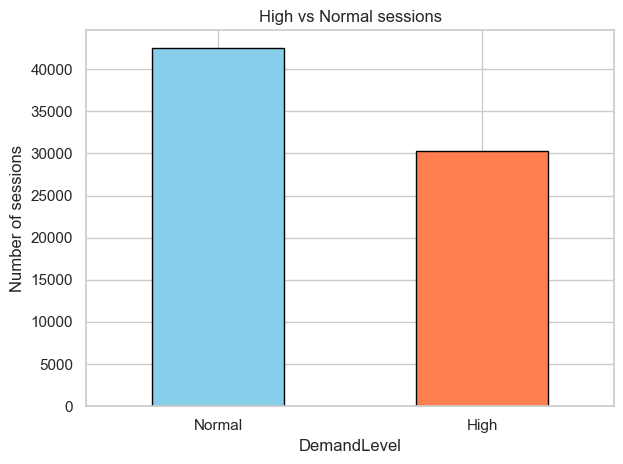

In [21]:
mean_demand = y_train.mean()

df["DemandLevel"] = np.where(
    df["Demand"] >= mean_demand, "High", "Normal"
)  # the new column

print(f"Mean demand (training data) = {mean_demand:.2f} kWh")

y_train_c = (df["DemandLevel"].iloc[:split] == "High").astype(int)  # High = 1, Normal = 0
y_test_c  = (df["DemandLevel"].iloc[split:] == "High").astype(int)

print(df["DemandLevel"].value_counts())
print((df["DemandLevel"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

df["DemandLevel"].value_counts().plot.bar(
    rot=0,
    color=["skyblue", "coral"],
    edgecolor="black",
    title="High vs Normal sessions"
)

plt.ylabel("Number of sessions")
plt.tight_layout()
plt.show()

The classes are **not equal** (High is the smaller group). We can fix this by **oversampling** the training data only (never the test data):
* **Random Oversampling** – copies existing High rows
* **SMOTE** – creates *new* High rows between similar ones
* **ADASYN** – like SMOTE, but focuses on the hard-to-learn rows

We test each on one quick model (LightGBM) and keep the best by **F1-score** (a balance of precision and recall).

In [23]:
samplers = {"None": None, "Random Oversampling": RandomOverSampler(random_state=42),
            "SMOTE": SMOTE(random_state=42), "ADASYN": ADASYN(random_state=42)}

imbalance_scores = {}
for name, sampler in samplers.items():
    steps = [StandardScaler()] + ([sampler] if sampler else []) + [LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)]
    pipe = make_pipeline(*steps).fit(X_train, y_train_c)
    pred = pipe.predict(X_test)
    imbalance_scores[name] = {"Precision": precision_score(y_test_c, pred), "Recall": recall_score(y_test_c, pred),
                              "F1": f1_score(y_test_c, pred), "ROC_AUC": roc_auc_score(y_test_c, pipe.predict_proba(X_test)[:, 1])}

imbalance_results = pd.DataFrame(imbalance_scores).T.round(3)
best_sampler = imbalance_results["F1"].idxmax()
sampler = samplers[best_sampler]
print("Technique chosen:", best_sampler)
imbalance_results

Technique chosen: ADASYN


,Precision,Recall,F1,ROC_AUC
None,0.669,0.691,0.680,0.814
Random Oversampling,0.638,0.771,0.698,0.811
SMOTE,0.636,0.776,0.699,0.811
ADASYN,0.600,0.845,0.702,0.807


## Step 8 – Classification: predict High or Normal


In [25]:
clf_models = {
    "Random Forest":       RandomForestClassifier(n_estimators=100, max_depth=14, min_samples_leaf=10, n_jobs=-1, random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
    "SVM":                 SVC(),
    "XGBoost":             XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42),
    "LightGBM":            LGBMClassifier(n_estimators=400, learning_rate=0.05, random_state=42, verbose=-1),
}

clf_pipes, clf_scores, clf_preds = {}, {}, {}
for name, model in clf_models.items():
    pipe = make_pipeline(*([StandardScaler()] + ([sampler] if sampler else []) + [model]))
    if name == "SVM":
        rows = X_train.sample(10000, random_state=42).index
        pipe.fit(X_train.loc[rows], y_train_c.loc[rows])
    else:
        pipe.fit(X_train, y_train_c)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_test)
    clf_pipes[name], clf_preds[name] = pipe, pred
    clf_scores[name] = {"Accuracy": accuracy_score(y_test_c, pred), "Precision": precision_score(y_test_c, pred),
                        "Recall": recall_score(y_test_c, pred), "F1": f1_score(y_test_c, pred), "ROC_AUC": roc_auc_score(y_test_c, prob)}

clf_results = pd.DataFrame(clf_scores).T.sort_values("F1", ascending=False).round(3)
clf_results

,Accuracy,Precision,Recall,F1,ROC_AUC
LightGBM,0.706,0.603,0.844,0.704,0.808
XGBoost,0.705,0.603,0.845,0.703,0.809
Random Forest,0.723,0.633,0.787,0.702,0.813
SVM,0.700,0.603,0.809,0.691,0.780
KNN,0.693,0.598,0.783,0.678,0.777


Best classification model: LightGBM  (F1 = 0.704, ROC-AUC = 0.808)


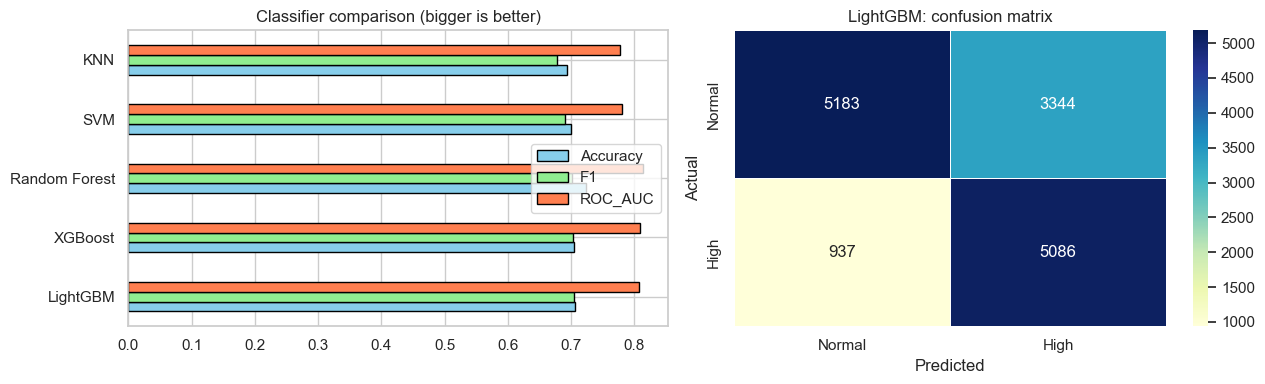

In [26]:
best_clf = clf_results["F1"].idxmax()

print(f"Best classification model: {best_clf}  (F1 = {clf_results.loc[best_clf, 'F1']}, ROC-AUC = {clf_results.loc[best_clf, 'ROC_AUC']})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

clf_results[["Accuracy", "F1", "ROC_AUC"]].plot.barh(
    ax=ax[0],
    title="Classifier comparison (bigger is better)",
    color=["skyblue", "lightgreen", "coral"],
    edgecolor="black"
)

sns.heatmap(
    confusion_matrix(y_test_c, clf_preds[best_clf]),
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    ax=ax[1],
    xticklabels=["Normal", "High"],
    yticklabels=["Normal", "High"],
    linewidths=0.5,
    linecolor="white"
)

ax[1].set(
    xlabel="Predicted",
    ylabel="Actual",
    title=f"{best_clf}: confusion matrix"
)

plt.tight_layout()
plt.show()

## Step 9 – Understanding Model Predictions


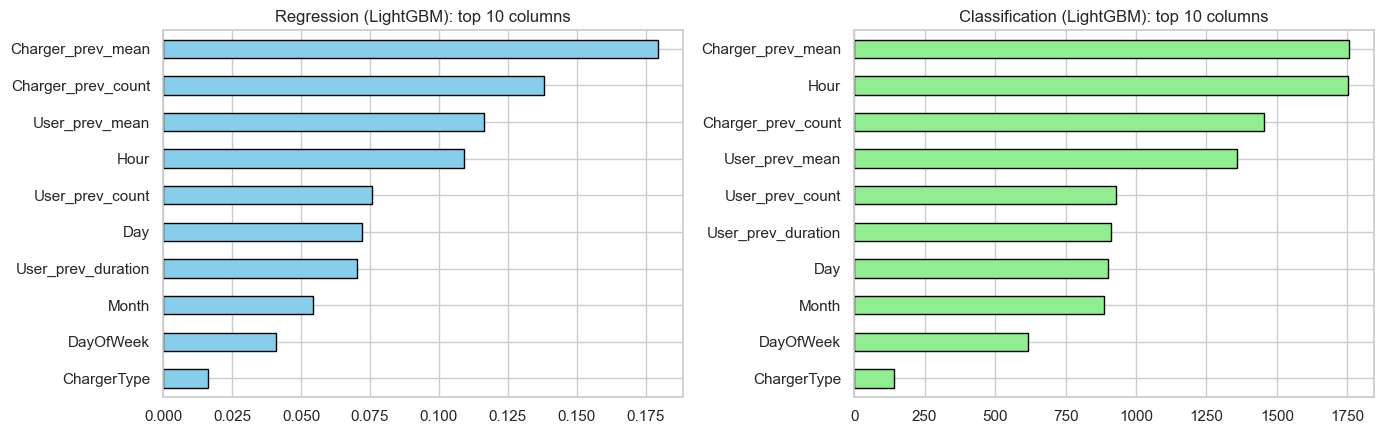

In [27]:
import shap
from lime.lime_tabular import LimeTabularExplainer

reg_pipe, clf_pipe = reg_pipes[best_reg], clf_pipes[best_clf]
reg_model, clf_model = reg_pipe[-1], clf_pipe[-1]  # the model inside each pipeline

reg_importance = pd.Series(
    reg_model.feature_importances_, index=X.columns
).sort_values(ascending=False)

reg_importance = reg_importance / reg_importance.sum()  # as shares that add up to 1

clf_importance = pd.Series(
    clf_model.feature_importances_, index=X.columns
).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

reg_importance.head(10)[::-1].plot.barh(
    ax=ax[0],
    title=f"Regression ({best_reg}): top 10 columns",
    color="skyblue",
    edgecolor="black"
)

clf_importance.head(10)[::-1].plot.barh(
    ax=ax[1],
    title=f"Classification ({best_clf}): top 10 columns",
    color="lightgreen",
    edgecolor="black"
)

plt.tight_layout()
plt.show()

### SHAP – regression model

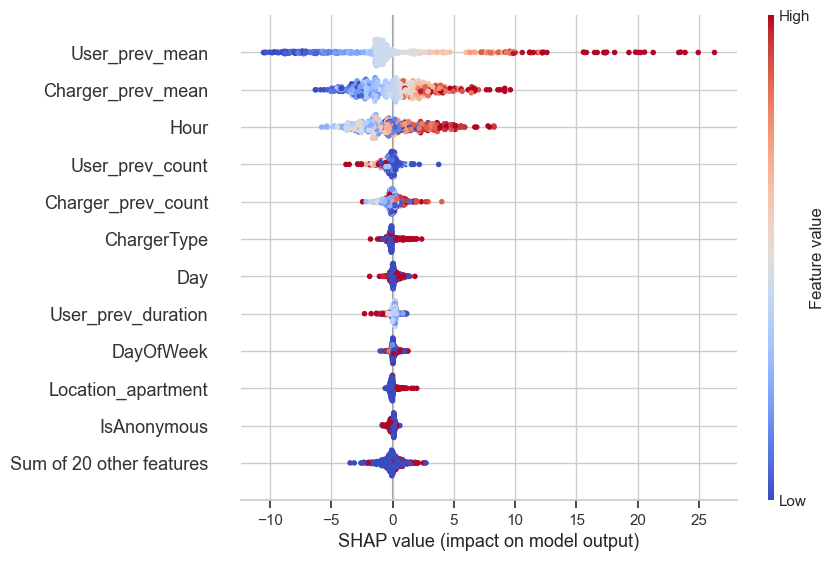

In [30]:
Xs_reg = pd.DataFrame(
    reg_pipe[0].transform(X_test.iloc[:500]),
    columns=X.columns
)  # 500 test rows (scaled)

sv_reg = shap.TreeExplainer(reg_model)(
    Xs_reg,
    check_additivity=False
)

shap.plots.beeswarm(
    sv_reg,
    max_display=12,
    color=plt.get_cmap("coolwarm")
)

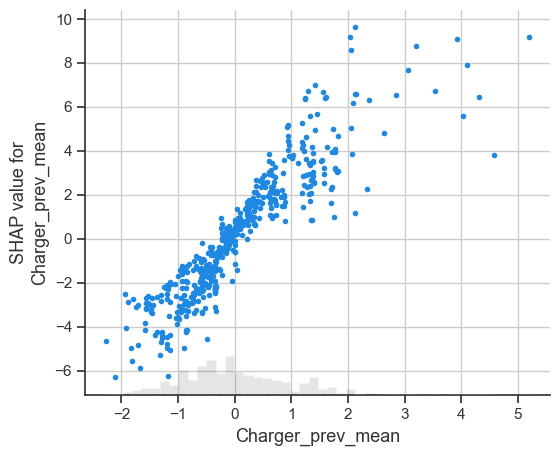

In [ ]:
shap.plots.scatter(sv_reg[:, reg_importance.index[0]])      

### SHAP – classification model

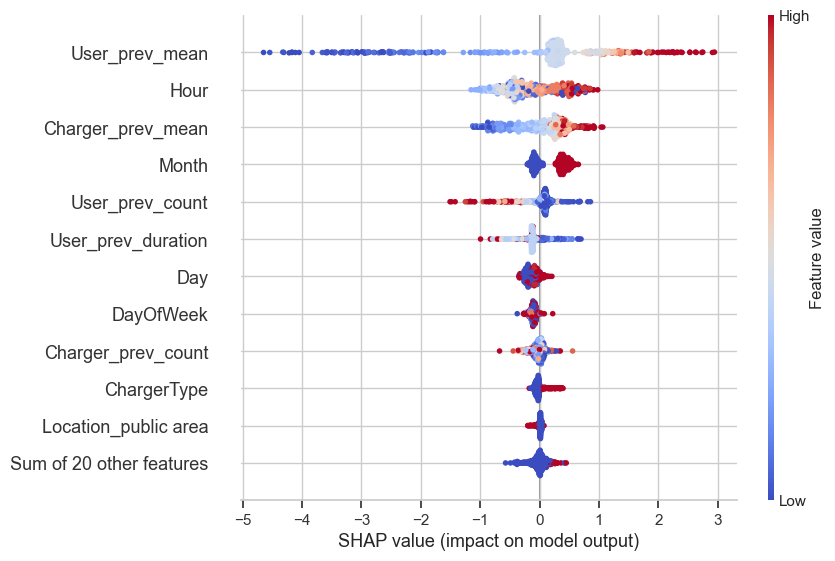

In [33]:
Xs_clf = pd.DataFrame(
    clf_pipe[0].transform(X_test.iloc[:500]),
    columns=X.columns
)

sv_clf = shap.TreeExplainer(clf_model)(
    Xs_clf,
    check_additivity=False
)

if sv_clf.values.ndim == 3:  # keep the "High" class
    sv_clf = sv_clf[:, :, 1]

shap.plots.beeswarm(
    sv_clf,
    max_display=12,
    color=plt.get_cmap("coolwarm")
)


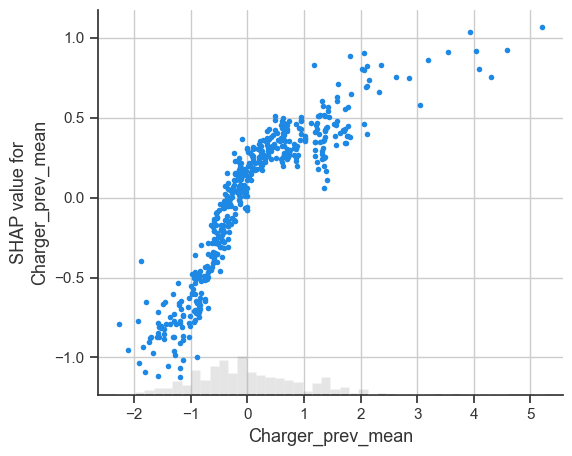

In [34]:
shap.plots.scatter(sv_clf[:, clf_importance.index[0]])

### LIME – explain one session

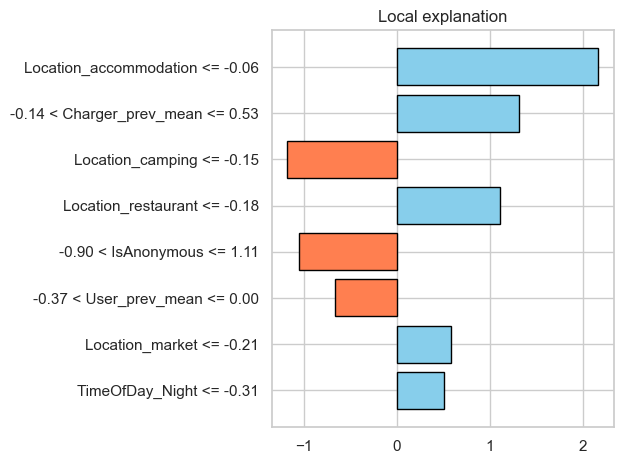

Predicted kWh: 19.9 | Actual kWh: 10.7


In [39]:
train_scaled = reg_pipe[0].transform(X_train)

lime_reg = LimeTabularExplainer(
    train_scaled,
    feature_names=list(X.columns),
    mode="regression"
)

exp = lime_reg.explain_instance(
    Xs_reg.values[0],
    reg_model.predict,
    num_features=8
)

fig = exp.as_pyplot_figure()

# Change bar colors
for bar in fig.axes[0].patches:
    bar.set_color("skyblue" if bar.get_width() >= 0 else "coral")
    bar.set_edgecolor("black")

plt.tight_layout()
plt.show()

print(
    "Predicted kWh:", round(reg_model.predict(Xs_reg.values[:1])[0], 1),
    "| Actual kWh:", round(y_test.iloc[0], 1)
)

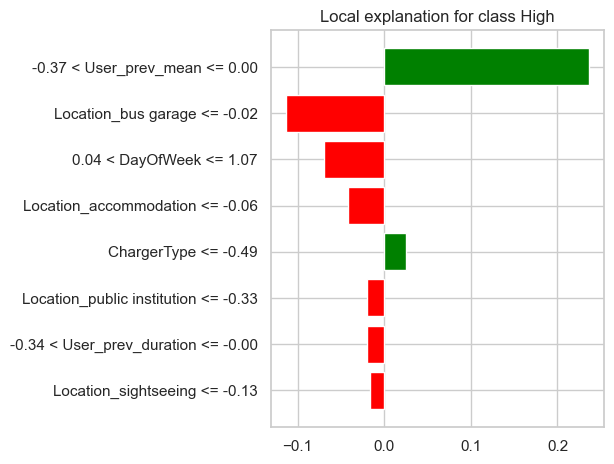

In [41]:
lime_clf = LimeTabularExplainer(clf_pipe[0].transform(X_train), feature_names=list(X.columns), mode="classification",
                                class_names=["Normal", "High"])
exp = lime_clf.explain_instance(Xs_clf.values[0], clf_model.predict_proba, num_features=8)
exp.as_pyplot_figure(); plt.tight_layout(); plt.show()

## Step 10 – Store the Trained Models Using Pickle


In [30]:
saved = {
    "reg_model": reg_pipes[best_reg], "reg_name": best_reg, "reg_results": reg_results,
    "reg_importance": reg_importance.head(10), "test_actual": y_test.values, "test_pred": reg_pred,
    "clf_model": clf_pipes[best_clf], "clf_name": best_clf, "clf_results": clf_results,
    "clf_importance": clf_importance.head(10), "imbalance_results": imbalance_results, "sampler_used": best_sampler,
    "columns": list(X.columns), "fill_values": fill_values, "mean_demand": mean_demand,
    "eda_data": df[["Start", "UserID", "ChargerID", "ChargerCompany", "ChargerType", "Location",
                    "Demand", "Duration", "Hour", "DayOfWeek", "Month", "DemandLevel"]],
}
with open("ev_models.pkl", "wb") as f:
    pickle.dump(saved, f)
print("Saved ev_models.pkl")

Saved ev_models.pkl


 ### Let's test the model: load the saved file and make a prediction for a test session.

In [42]:
with open("ev_models.pkl", "rb") as f:
    loaded = pickle.load(f)

# Test with the second session
one_session = X_test.iloc[[1]]

print(
    "Predicted energy:",
    round(loaded["reg_model"].predict(one_session)[0], 1),
    "kWh   (actual:",
    round(y_test.iloc[1], 1),
    "kWh)"
)

print(
    "Chance of 'High':",
    round(loaded["clf_model"].predict_proba(one_session)[0, 1] * 100),
    "%   (actual:",
    df["DemandLevel"].iloc[split + 1],
    ")"
)

Predicted energy: 13.6 kWh   (actual: 10.0 kWh)
Chance of 'High': 37 %   (actual: Normal )
